# Charlotte Traffic Data Preparation 
This notebook prepares traffic data collected from the TomTom Traffic API for storage in AWS S3 and machine learning.

In [1]:
import pandas as pd 

## 1. Load the Dataset
Load the Charlotte traffic data collected from the TomTom Traffic API.

In [2]:
df = pd.read_csv("charlotte_traffic.csv")


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (4600, 29)

Column names:
['timestamp', 'date', 'day_of_week', 'hour', 'minute', 'is_weekend', 'is_rush_hour', 'location', 'road', 'road_type', 'latitude', 'longitude', 'snapped_latitude', 'snapped_longitude', 'road_class_frc', 'current_speed_mph', 'free_flow_speed_mph', 'current_travel_time_s', 'free_flow_travel_time_s', 'delay_s', 'confidence', 'road_closure', 'speed_ratio', 'temperature_f', 'precipitation_in', 'is_raining', 'weather_code', 'wind_speed_mph', 'traffic_level']

First 5 rows:


,timestamp,date,day_of_week,hour,minute,is_weekend,is_rush_hour,location,road,road_type,...,delay_s,confidence,road_closure,speed_ratio,temperature_f,precipitation_in,is_raining,weather_code,wind_speed_mph,traffic_level
0,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Arrowood Rd,I-77,interstate,...,68,1.0,False,0.34,70.8,0,False,0,6.5,high
1,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Tyvola Rd,I-77,interstate,...,99,1.0,False,0.55,70.8,0,False,0,6.5,medium
2,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at John Belk Fwy,I-77,interstate,...,135,1.0,False,0.26,70.8,0,False,0,6.5,high
3,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at LaSalle St,I-77,interstate,...,0,1.0,False,1.00,70.8,0,False,0,6.5,low
4,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Sunset Rd,I-77,interstate,...,0,1.0,False,1.00,70.8,0,False,0,6.5,low


## 2. Inspect the Dataset
Check the structure and data types of the traffic dataset.

In [4]:
print("Dataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                4600 non-null   str    
 1   date                     4600 non-null   str    
 2   day_of_week              4600 non-null   str    
 3   hour                     4600 non-null   int64  
 4   minute                   4600 non-null   int64  
 5   is_weekend               4600 non-null   bool   
 6   is_rush_hour             4600 non-null   bool   
 7   location                 4600 non-null   str    
 8   road                     4600 non-null   str    
 9   road_type                4600 non-null   str    
 10  latitude                 4600 non-null   float64
 11  longitude                4600 non-null   float64
 12  snapped_latitude         4600 non-null   float64
 13  snapped_longitude        4600 non-null   float64
 14  road_class_frc

,timestamp,date,day_of_week,hour,minute,is_weekend,is_rush_hour,location,road,road_type,...,delay_s,confidence,road_closure,speed_ratio,temperature_f,precipitation_in,is_raining,weather_code,wind_speed_mph,traffic_level
count,4600,4600,4600,4600.000000,4600.000000,4600,4600,4600,4600,4600,...,4600.000000,4600.000000,4600,4600.000000,4600.000000,4600.0,4600,4600.000000,4600.000000,4600
unique,184,7,6,NaN,NaN,2,2,25,12,2,...,NaN,NaN,2,NaN,NaN,NaN,1,NaN,NaN,3
top,2026-09-26 12:17:53,2026-11-14,Saturday,NaN,NaN,True,False,I-77 at Arrowood Rd,I-77,interstate,...,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN,low
freq,25,1200,1300,NaN,NaN,2475,4175,184,920,3128,...,NaN,NaN,4598,NaN,NaN,NaN,4600,NaN,NaN,4098
mean,NaN,NaN,NaN,11.994565,27.266304,NaN,NaN,NaN,NaN,NaN,...,9.245000,0.999813,NaN,0.947974,45.701087,0.0,NaN,0.141304,6.479891,NaN
std,NaN,NaN,NaN,6.556906,17.439042,NaN,NaN,NaN,NaN,NaN,...,39.584329,0.008991,NaN,0.151835,10.140892,0.0,NaN,0.533332,3.126297,NaN
min,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.500000,NaN,0.000000,29.000000,0.0,NaN,0.000000,0.500000,NaN
25%,NaN,NaN,NaN,7.000000,10.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,1.000000,NaN,1.000000,37.000000,0.0,NaN,0.000000,4.100000,NaN
50%,NaN,NaN,NaN,12.000000,30.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,1.000000,NaN,1.000000,45.450000,0.0,NaN,0.000000,5.400000,NaN
75%,NaN,NaN,NaN,17.250000,41.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,1.000000,NaN,1.000000,52.750000,0.0,NaN,0.000000,8.625000,NaN


## 3. Check Missing Values
Identify missing values that may affect the analysis or machine learning model.

In [5]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values before cleaning:
timestamp                  0
date                       0
day_of_week                0
hour                       0
minute                     0
is_weekend                 0
is_rush_hour               0
location                   0
road                       0
road_type                  0
latitude                   0
longitude                  0
snapped_latitude           0
snapped_longitude          0
road_class_frc             0
current_speed_mph          0
free_flow_speed_mph        0
current_travel_time_s      0
free_flow_travel_time_s    0
delay_s                    0
confidence                 0
road_closure               0
speed_ratio                0
temperature_f              0
precipitation_in           0
is_raining                 0
weather_code               0
wind_speed_mph             0
traffic_level              0
dtype: int64

Total missing values: 0


## 4. Remove Duplicate Records
Check for duplicate API records and remove them if necessary.

In [6]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Dataset shape: (4600, 29)


### Remove Overlapping Collection Runs
On Nov 13, two collectors ran at the same time, so three snapshot runs are near-duplicates of runs taken a few minutes earlier. Remove those 3 runs (25 rows each, 75 rows total).

In [ ]:
overlap_runs = [
    "2026-11-13 08:00:43",
    "2026-11-13 20:50:47",
    "2026-11-13 21:45:38",
]

rows_before = len(df)
df = df[~df["timestamp"].astype(str).isin(overlap_runs)].copy()

print("Overlapping rows removed:", rows_before - len(df))
print("Dataset shape:", df.shape)

## 5. Standardize Column Names
Standardize column names so they are easier to use in Python and machine learning.

In [7]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
      .str.replace("-", "_")
)

print("Updated columns:")
print(df.columns.tolist())

Updated columns:
['timestamp', 'date', 'day_of_week', 'hour', 'minute', 'is_weekend', 'is_rush_hour', 'location', 'road', 'road_type', 'latitude', 'longitude', 'snapped_latitude', 'snapped_longitude', 'road_class_frc', 'current_speed_mph', 'free_flow_speed_mph', 'current_travel_time_s', 'free_flow_travel_time_s', 'delay_s', 'confidence', 'road_closure', 'speed_ratio', 'temperature_f', 'precipitation_in', 'is_raining', 'weather_code', 'wind_speed_mph', 'traffic_level']


## 6. Clean Text Values
Remove unnecessary spaces and standardize text values.

In [8]:
text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

print("Text columns cleaned:")
print(text_columns.tolist())

Text columns cleaned:
['timestamp', 'date', 'day_of_week', 'location', 'road', 'road_type', 'road_class_frc', 'traffic_level']


/var/folders/5g/k3249q516xzcmcvfpw3sjwwm0000gn/T/ipykernel_15612/2420903518.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


## 7. Prepare Date and Time
Convert the API timestamp into datetime format and create time-based features.

In [9]:
if "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

    df["hour"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.day_name()
    df["is_weekend"] = df["timestamp"].dt.dayofweek >= 5

    print("Time features created.")
    display(df[["timestamp", "hour", "day_of_week", "is_weekend"]].head())
else:
    print("Timestamp column not found.")

Time features created.


,timestamp,hour,day_of_week,is_weekend
0,2026-09-26 12:17:53,12,Saturday,True
1,2026-09-26 12:17:53,12,Saturday,True
2,2026-09-26 12:17:53,12,Saturday,True
3,2026-09-26 12:17:53,12,Saturday,True
4,2026-09-26 12:17:53,12,Saturday,True


## 8. Validate Numeric Data
Check numeric traffic measurements for invalid negative values.

In [10]:
numeric_columns = df.select_dtypes(include="number").columns

print("Numeric columns:")
print(numeric_columns.tolist())

for column in numeric_columns:
    negative_count = (df[column] < 0).sum()
    print(column, "- negative values:", negative_count)

Numeric columns:
['hour', 'minute', 'latitude', 'longitude', 'snapped_latitude', 'snapped_longitude', 'current_speed_mph', 'free_flow_speed_mph', 'current_travel_time_s', 'free_flow_travel_time_s', 'delay_s', 'confidence', 'speed_ratio', 'temperature_f', 'precipitation_in', 'weather_code', 'wind_speed_mph']
hour - negative values: 0
minute - negative values: 0
latitude - negative values: 0
longitude - negative values: 4600
snapped_latitude - negative values: 0
snapped_longitude - negative values: 4600
current_speed_mph - negative values: 0
free_flow_speed_mph - negative values: 0
current_travel_time_s - negative values: 0
free_flow_travel_time_s - negative values: 0
delay_s - negative values: 0
confidence - negative values: 0
speed_ratio - negative values: 0
temperature_f - negative values: 0
precipitation_in - negative values: 0
weather_code - negative values: 0
wind_speed_mph - negative values: 0


## 9. Check Traffic Congestion Levels
Review the distribution of traffic congestion levels in the API dataset.

In [11]:
if "traffic_level" in df.columns:
    print("Traffic level distribution:")
    print(df["traffic_level"].value_counts())

    print("\nTraffic level percentages:")
    print(df["traffic_level"].value_counts(normalize=True).mul(100).round(1))
else:
    print("traffic_level column not found.")

Traffic level distribution:
traffic_level
low       4098
medium     330
high       172
Name: count, dtype: int64

Traffic level percentages:
traffic_level
low       89.1
medium     7.2
high       3.7
Name: proportion, dtype: float64


## 10. Visualize Traffic Levels
Visualize the distribution of congestion levels in the collected traffic data.

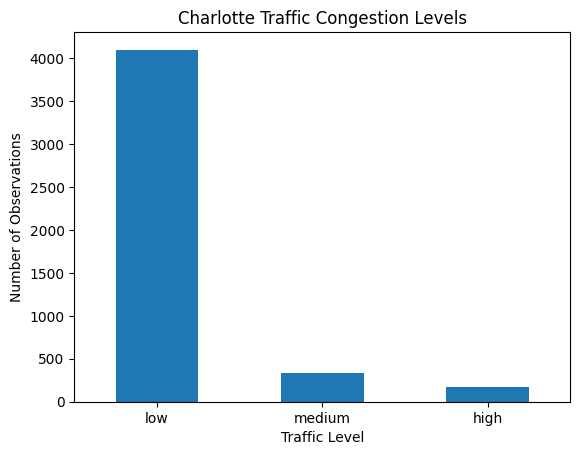

In [12]:
import matplotlib.pyplot as plt

if "traffic_level" in df.columns:
    df["traffic_level"].value_counts().plot(kind="bar")

    plt.title("Charlotte Traffic Congestion Levels")
    plt.xlabel("Traffic Level")
    plt.ylabel("Number of Observations")
    plt.xticks(rotation=0)
    plt.show()

11. Average Traffic Speed By Hour

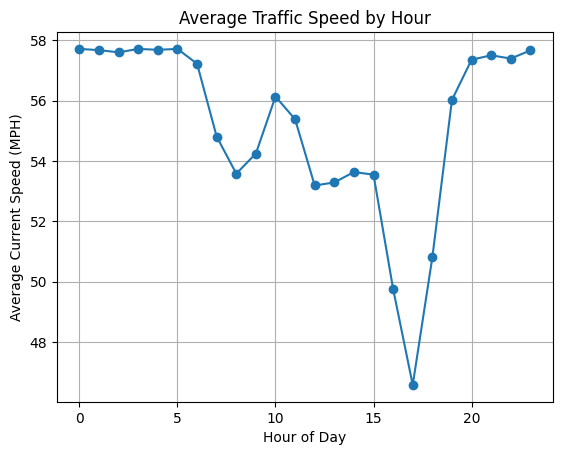

In [13]:
avg_speed_by_hour = df.groupby("hour")["current_speed_mph"].mean()

avg_speed_by_hour.plot(kind="line", marker="o")

plt.title("Average Traffic Speed by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Current Speed (MPH)")
plt.grid(True)
plt.show()

12. Final Data Quality Check

In [14]:
print("Final dataset shape:", df.shape)


Final dataset shape: (4600, 29)


In [15]:

print("\nMissing values:")
print(df.isnull().sum())



Missing values:
timestamp                  0
date                       0
day_of_week                0
hour                       0
minute                     0
is_weekend                 0
is_rush_hour               0
location                   0
road                       0
road_type                  0
latitude                   0
longitude                  0
snapped_latitude           0
snapped_longitude          0
road_class_frc             0
current_speed_mph          0
free_flow_speed_mph        0
current_travel_time_s      0
free_flow_travel_time_s    0
delay_s                    0
confidence                 0
road_closure               0
speed_ratio                0
temperature_f              0
precipitation_in           0
is_raining                 0
weather_code               0
wind_speed_mph             0
traffic_level              0
dtype: int64


In [16]:

print("\nDuplicate rows:")
print(df.duplicated().sum())



Duplicate rows:
0


In [17]:

print("\nFinal columns:")
print(df.columns.tolist())



Final columns:
['timestamp', 'date', 'day_of_week', 'hour', 'minute', 'is_weekend', 'is_rush_hour', 'location', 'road', 'road_type', 'latitude', 'longitude', 'snapped_latitude', 'snapped_longitude', 'road_class_frc', 'current_speed_mph', 'free_flow_speed_mph', 'current_travel_time_s', 'free_flow_travel_time_s', 'delay_s', 'confidence', 'road_closure', 'speed_ratio', 'temperature_f', 'precipitation_in', 'is_raining', 'weather_code', 'wind_speed_mph', 'traffic_level']


In [18]:

display(df.head())

,timestamp,date,day_of_week,hour,minute,is_weekend,is_rush_hour,location,road,road_type,...,delay_s,confidence,road_closure,speed_ratio,temperature_f,precipitation_in,is_raining,weather_code,wind_speed_mph,traffic_level
0,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Arrowood Rd,I-77,interstate,...,68,1.0,False,0.34,70.8,0,False,0,6.5,high
1,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Tyvola Rd,I-77,interstate,...,99,1.0,False,0.55,70.8,0,False,0,6.5,medium
2,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at John Belk Fwy,I-77,interstate,...,135,1.0,False,0.26,70.8,0,False,0,6.5,high
3,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at LaSalle St,I-77,interstate,...,0,1.0,False,1.00,70.8,0,False,0,6.5,low
4,2026-09-26 12:17:53,2026-09-26,Saturday,12,17,True,False,I-77 at Sunset Rd,I-77,interstate,...,0,1.0,False,1.00,70.8,0,False,0,6.5,low


13. Save the Prepared Dataset

In [19]:
df.to_csv("cleaned_charlotte_traffic.csv", index=False)

print("cleaned_charlotte_traffic.csv saved successfully!")

cleaned_charlotte_traffic.csv saved successfully!
